# SkillBridge AI — Career recommendation and skill gap
## 1. Overview
Explore digital career families based on skills in Indonesian job postings. SDG 4.4 and 8.5. No hiring outcome labels; recommendations are exploratory.

In [1]:
from pathlib import Path
import sys
root=Path.cwd()
if not (root/'src').exists(): root=root.parent
sys.path.insert(0,str(root))
import pandas as pd
from src.core import load,recommend,gap,explain,learning_rank
b=load(); d=pd.read_csv(root/'data/processed/jobs.csv')
print('Local profiles:',len(d),'Default:',b['best'])

Local profiles: 2838 Default: Hybrid


## 2. EDA
Counts represent retained unique role-skill profiles, not market share.

career,Data & AI,Design,Digital Marketing,Infrastructure & Security,Software Development
source,,,,,
Glints Indonesia,46,0,0,2,0
Indonesia Kaggle,91,106,206,199,1160
Web Developer,31,32,42,18,905


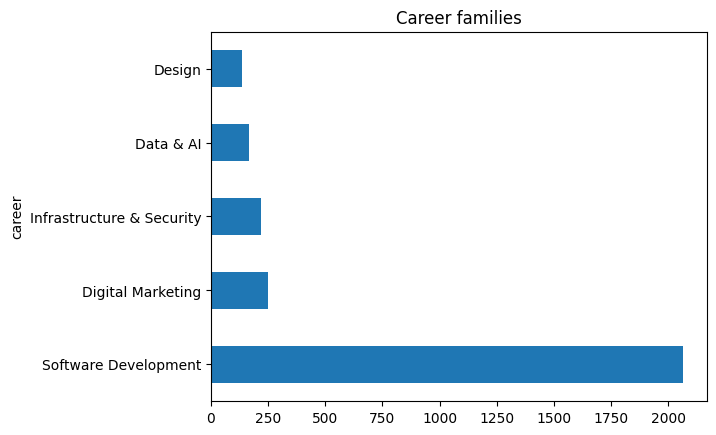

In [2]:
display(pd.crosstab(d.source,d.career))
d.career.value_counts().plot.barh(title='Career families');

## 3. Preprocessing
Title-derived labels; skills only as features. Exact duplicate role-skill profiles removed. Grouped by identical skill sets. TF-IDF fitted within training folds.

In [3]:
display(pd.read_csv(root/'results/data_audit.csv'))
display(pd.crosstab(d.career,d.split))
assert not set(d[d.split=='development'].group)&set(d[d.split=='test'].group)
display(pd.read_csv(root/"results/similarity_audit.csv"))
display(pd.read_csv(root/"results/label_audit.csv"))

,source,raw,mapped,recognized,unique,usage
0,Indonesia Kaggle,5374,2763.0,2600.0,1762.0,local
1,Web Developer,2649,2222.0,1903.0,1163.0,local
2,Glints Indonesia,166,78.0,74.0,53.0,local
3,International IT,10000,3796.0,3693.0,3126.0,augmentation candidate
4,LinkedIn metadata,12217,NaN,NaN,NaN,excluded: no skills or descriptions
5,Digital gap jobs,15247,NaN,NaN,NaN,excluded: template concerns
6,Digital gap courses,3892,NaN,NaN,NaN,reference only
7,IT sentences,776,NaN,NaN,NaN,vocabulary audit only


split,development,test
career,,
Data & AI,135,33
Design,110,28
Digital Marketing,198,50
Infrastructure & Security,176,43
Software Development,1652,413


,exclude_similarity_at_or_above,retained_test,excluded_test,accuracy,macro_f1
0,1.01,567,0,0.932981,0.872323
1,1.00,567,0,0.932981,0.872323
2,0.90,564,3,0.932624,0.870713
3,0.80,512,55,0.927734,0.863597
4,0.70,416,151,0.918269,0.861427


,source,career,profiles,ambiguous_profiles
0,Glints Indonesia,Data & AI,46,5
1,Glints Indonesia,Infrastructure & Security,2,1
2,Indonesia Kaggle,Data & AI,91,7
3,Indonesia Kaggle,Design,106,22
4,Indonesia Kaggle,Digital Marketing,206,19
5,Indonesia Kaggle,Infrastructure & Security,199,21
6,Indonesia Kaggle,Software Development,1160,26
7,Web Developer,Data & AI,31,0
8,Web Developer,Design,32,6
9,Web Developer,Digital Marketing,42,6


## 4. Training & Testing
Reproduce by running `python -m src.train` from project root. Four-fold grouped development CV selects configurations; holdout reports retrospective performance. Broad family classification is not directly comparable to V1 fine labels.
Optional full reproduction from a root terminal: `python -m src.train`. The saved notebook reads the same fitted artifacts as Streamlit.

In [4]:
display(pd.read_csv(root/'results/metrics.csv').round(4))
display(pd.read_csv(root/'results/gap_evaluation.csv')[['global_hit','oracle_hit','end_to_end_hit']].mean())
display(pd.read_csv(root/'results/robustness.csv'))
display(pd.read_csv(root/'results/bootstrap_ci.csv'))
display(pd.read_csv(root/'results/gap_tuning.csv'))
display(pd.read_csv(root/'results/source_holdout.csv'))
display(pd.read_csv(root/"results/gap_v3_tuning.csv"))
display(pd.read_csv(root/"results/gap_v3_evaluation.csv")[["hit5","hit10","reciprocal_rank"]].mean())

,model,split,accuracy,macro_f1,top3_hit,mrr,ndcg_at3
0,Naive Bayes,grouped CV,0.9106,0.8108,0.9947,0.9510,0.9614
1,Naive Bayes,test,0.9259,0.8504,1.0000,0.9612,0.9713
2,Logistic Regression,grouped CV,0.8617,0.7695,0.9908,0.9246,0.9402
3,Logistic Regression,test,0.8836,0.8141,0.9965,0.9368,0.9516
4,Linear SVM,grouped CV,0.8978,0.8044,0.9881,0.9422,0.9521
5,Linear SVM,test,0.9206,0.8621,0.9982,0.9563,0.9668
6,Random Forest,grouped CV,0.9014,0.7988,0.9930,0.9455,0.9566
7,Random Forest,test,0.9153,0.8336,0.9965,0.9561,0.9661
8,Majority baseline,grouped CV,0.7274,0.1684,0.8921,0.8214,0.8212
9,Majority baseline,test,0.7284,0.1686,0.8924,0.8222,0.8220


global_hit        0.261993
oracle_hit        0.446494
end_to_end_hit    0.424354
dtype: float64

,retained_fraction,accuracy,macro_f1,top3_hit,mrr,ndcg_at3
0,0.50,0.904762,0.821728,0.994709,0.948618,0.959665
1,0.75,0.925926,0.858049,0.998236,0.960758,0.970163
2,1.00,0.932981,0.872323,0.996473,0.964433,0.972116


,Unnamed: 0,accuracy,macro_f1,top3_hit,mrr,ndcg_at3
0,0.025,0.910689,0.827110,0.991218,0.951204,0.962273
1,0.975,0.953826,0.908331,1.000000,0.975285,0.980863


,policy,cv_oracle_hit_at5,n
0,frequency,0.378155,2179
1,0.25,0.414410,2179
2,0.5,0.431849,2179
3,0.75,0.445617,2179
4,1.0,0.458926,2179


,held_out_source,train_profiles,test_profiles,test_classes,accuracy,macro_f1,top3_hit,mrr,ndcg_at3
0,Glints Indonesia,2230,7,1,0.714286,0.416667,1.000000,0.857143,0.894551
1,Indonesia Kaggle,870,361,5,0.883657,0.801393,0.988920,0.933564,0.946081
2,Web Developer,1442,199,5,0.949749,0.862949,0.994975,0.972529,0.977625


,policy,cv_end_to_end_hit5,n
0,frequency,0.364387,2179
1,conditional,0.445617,2179
2,neighbor,0.463056,2179
3,blend,0.456173,2179
4,neighbor_frequency,0.445617,2179


hit5               0.446494
hit10              0.643911
reciprocal_rank    0.319855
dtype: float64

## 5. Prediction
Same model and functions as Streamlit. Coverage is weighted skill overlap, not hiring probability.

In [5]:
user_skills=['Python','SQL','Pandas','Statistics','Power BI']
r=recommend(b,user_skills);display(r.head(3))
career=r.iloc[0].Career
display(learning_rank(b,career,user_skills).head(5))
display(explain(b,user_skills,career))

,Career,Model score,Skill coverage
0,Data & AI,0.819186,0.325885
1,Software Development,0.097874,0.080507
2,Infrastructure & Security,0.081872,0.073964


,Skill,Demand share,Learning priority score
0,Tableau,0.177778,0.267664
1,Data analysis,0.274074,0.235409
2,Machine learning,0.170370,0.196896
3,Excel,0.155556,0.159972
4,Data visualization,0.096296,0.139671


,Skill,Score change when removed
4,Power BI,0.052675
3,Statistics,0.048782
2,Pandas,0.034198
0,Python,0.000836
1,SQL,-0.048371
